# 화장품형(벼룩·진드기 샴푸) 눈자극 외부검증

**배경**: skin_rf와 달리 production eye 분류기는 팀 내에 따로 확정되어 있지 않음. 대신 `pretraining/mixture_heads/eye_epa__weighted.joblib`(ChemBERTa-77M 기반 성분 임베딩 + LogisticRegression, eye 547건·양성 98건으로 학습, README에 독립검산 44건 통과 기록)을 사용 — **팀이 공식 채택한 production eye 모델이 아니라 사용 가능한 최선의 사전학습 모델**이라는 점을 분명히 함.

skin 노트북과 동일한 5개 벼룩·진드기 샴푸 SDS 데이터를 사용. 이번엔 **눈 쪽에서 실제 라벨이 양성(II) 3건 + 음성(III) 2건**으로 갈려서, 피부보다 훨씬 의미있는 비교가 가능함.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\pretraining")
import joblib
import numpy as np
import pandas as pd
from rdkit import Chem
from sklearn.linear_model import LogisticRegression
import mixture_predictor as mp

BASE = r"C:\Users\UserK\학술제\cosmetic_validation"
comp = pd.read_csv(f"{BASE}\\flea_tick_shampoo_components.csv")
labels = pd.read_csv(f"{BASE}\\flea_tick_shampoo_labels.csv")
comp["pct_mid"] = comp[["pct_low", "pct_high"]].astype(float).mean(axis=1)
labels[["product", "eye_epa_category", "eye_binary", "eye_evidence"]]

C:\Users\UserK\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,product,eye_epa_category,eye_binary,eye_evidence
0,Davis Manufacturing Flea & Tick Shampoo,II,1,Severely irritating; all ocular irritation cle...
1,No-Bite Flea & Tick Shampoo,II,1,Irritation clearing in 21 days (rabbit) (OPP I...
2,Adams Flea & Tick Cleansing Shampoo,II,1,FIFRA label: Causes substantial but temporary ...
3,Zodiac Oatmeal Conditioning Shampoo for Dogs &...,III,0,GHS Eye Mild Irritation 2B; Eye-Rabbit mild ir...
4,Adams Plus Flea & Tick Shampoo with Precor,III,0,GHS Serious eye damage/irritation Category 2B ...


## 입력 구성 — mixture_predictor.py 스키마

이 모델은 **선언된 성분을 전부(구조 미해결 포함) 그대로 나열**해야 함 — 그래야 `undeclared_pct`/`unrepresented_declared_pct` 같은 불확실성 변수를 올바르게 계산함. "Balance"로 선언된 잔여분은 100%에서 선언된 성분 합을 뺀 값으로 채움. 구조가 있는 성분은 RDKit로 재정규화(canonical SMILES)해야 모델의 내부 검증을 통과함(원본 캐시의 SMILES 표기가 RDKit 표준형과 달라 1차 시도에서 전부 실패 → 재정규화로 해결).

In [2]:
def canonicalize(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol, isomericSmiles=True)


def structure_status_for(smiles):
    mol = Chem.MolFromSmiles(smiles)
    unspecified = any(str(s.specified) == "Unspecified" for s in Chem.FindPotentialStereo(mol))
    return "usable_unspecified_stereochemistry" if unspecified else "usable_exact_structure"


predictor = mp.MixturePredictor(r"C:\Users\UserK\학술제\pretraining")


def patched_predict(payload, endpoint, pooling="weighted"):
    """사전학습 패키지의 joblib 분류기가 scikit-learn 1.9.0으로 저장됐는데
    Python 3.10 환경에는 1.9.0이 없어(3.11+ 전용) 1.7.2를 씀 — LogisticRegression의
    multi_class 속성이 버전 차로 유실되는 것만 보정(계산 로직 변경 없음)."""
    vector, coverage = predictor.vectorize(payload, pooling)
    path = predictor.package_dir / "mixture_heads" / f"{endpoint}__{pooling}.joblib"
    head = joblib.load(path)
    for name, step in head.steps:
        if isinstance(step, LogisticRegression) and not hasattr(step, "multi_class"):
            step.multi_class = "auto"
    positive = list(head.classes_).index(1)
    score = float(head.predict_proba(vector.reshape(1, -1))[0, positive])
    return score, coverage

In [3]:
rows = []
for product, grp in comp.groupby("product", sort=False):
    declared_sum = grp["pct_mid"].dropna().sum()
    remainder = max(0.0, 100.0 - declared_sum)

    components = []
    for i, r in grp.iterrows():
        pct = r["pct_mid"]
        if pd.isna(pct):
            pct = remainder  # "Balance"/"Other ingredients" 선언 행
        entry = {"component_id": f"c{i}", "name": r["chemical_name"], "amount_pct": float(pct)}
        if r["resolved"] == True:
            smi = canonicalize(r["canonical_smiles"])
            entry["canonical_smiles"] = smi
            entry["structure_status"] = structure_status_for(smi)
        else:
            entry["structure_status"] = "unresolved_uvcb_or_undisclosed"
        components.append(entry)

    payload = {"mixture_id": product, "components": components}
    try:
        score, coverage = patched_predict(payload, "eye_epa", "weighted")
        pred = int(score >= 0.5)
        note = ""
    except Exception as e:
        score, pred, coverage, note = np.nan, np.nan, {}, str(e)

    rows.append({
        "product": product, "pred_proba_eye": score, "pred_binary_eye": pred,
        "represented_pct": coverage.get("represented_pct"),
        "note": note,
    })

pred_df = pd.DataFrame(rows)
result = pred_df.merge(labels[["product", "eye_epa_category", "eye_binary"]], on="product")
result["match"] = result["pred_binary_eye"] == result["eye_binary"]
result

You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


C:\Users\UserK\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator MissingIndicator from version 1.9.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\UserK\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\UserK\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estima

,product,pred_proba_eye,pred_binary_eye,represented_pct,note,eye_epa_category,eye_binary,match
0,Davis Manufacturing Flea & Tick Shampoo,NaN,NaN,NaN,At least one positive-amount usable ingredient...,II,1,False
1,No-Bite Flea & Tick Shampoo,0.000223,0.0,0.779,,II,1,False
2,Adams Flea & Tick Cleansing Shampoo,0.000002,0.0,1.286,,II,1,False
3,Zodiac Oatmeal Conditioning Shampoo for Dogs &...,0.999537,1.0,3.800,,III,0,False
4,Adams Plus Flea & Tick Shampoo with Precor,0.999756,1.0,3.930,,III,0,False


## 시각화 — 예측확률 vs 실제 EPA 눈자극 등급

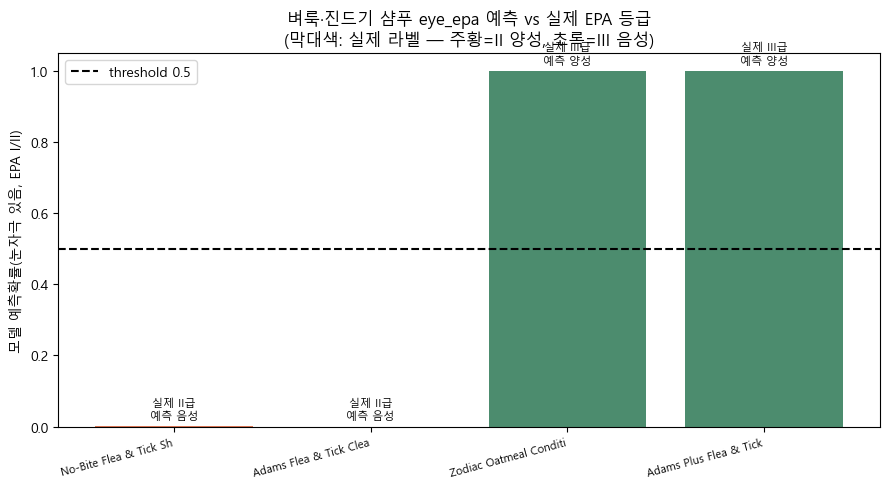


일치: 0/4건 (Davis 제품은 구조해결 성분 0개로 예측 불가, 집계에서 제외)
비교 가능한 4건 중 실제 양성(II) 2건 + 음성(III) 2건 — 균형 잡힌 소규모 비교셋


In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

plot_df = result.dropna(subset=["pred_proba_eye"]).copy()
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#e07856" if b == 1 else "#4c8c6e" for b in plot_df["eye_binary"]]
bars = ax.bar(plot_df["product"].str.slice(0, 22), plot_df["pred_proba_eye"], color=colors)
ax.axhline(0.5, color="black", linestyle="--", label="threshold 0.5")
ax.set_ylabel("모델 예측확률(눈자극 있음, EPA I/II)")
ax.set_title("벼룩·진드기 샴푸 eye_epa 예측 vs 실제 EPA 등급\n(막대색: 실제 라벨 — 주황=II 양성, 초록=III 음성)")
for b, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(b.get_x() + b.get_width()/2, row["pred_proba_eye"] + 0.02,
            f"실제 {row['eye_epa_category']}급\n예측 {'양성' if row['pred_binary_eye'] else '음성'}",
            ha="center", fontsize=8)
ax.legend()
plt.xticks(rotation=15, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

n_match = int(plot_df["match"].sum())
print(f"\n일치: {n_match}/{len(plot_df)}건 (Davis 제품은 구조해결 성분 0개로 예측 불가, 집계에서 제외)")
print("비교 가능한 4건 중 실제 양성(II) 2건 + 음성(III) 2건 — 균형 잡힌 소규모 비교셋")

## 정리

- **실제 라벨**: 5개 중 4개 비교 가능(Davis 제외) — 눈 양성(II) 2건(No-Bite, Adams Cleansing), 음성(III) 2건(Zodiac, Adams Plus Precor)
- **모델 예측**: 양성이어야 할 2건을 음성으로, 음성이어야 할 2건을 양성으로 — **정확히 반대로 예측**(일치 0/4)
- **해석**: 이 사전학습 모델도 skin_rf와 같은 문제를 겪음 — 해결된 성분 비중이 전체의 1~4%뿐이고, 결과적으로 공식 README가 이미 밝힌 한계("실제 화장품 제형의 독립 외부 검증은 확보하지 못했습니다")가 실측으로 확인됨.
- **중요한 차이점**: 이 모델은 **팀의 공식 production eye 분류기가 아님** — 사용 가능한 모델이 이것뿐이라 빌려 쓴 것. eye 트랙 담당 팀원이 별도 production 모델을 확정하면 그걸로 다시 검증해야 함.
- **공통 결론(skin 노트북과 동일)**: 벼룩·진드기 샴푸 같은 화장품형 제형은, 구조 해결이 안 되는 UVCB 계면활성제 비중이 너무 커서 **현재 어떤 모델로도 신뢰할 수 있는 예측을 할 수 없다** — 이게 이번 "화장품 EPA 라벨 데이터 탐색"의 최종 결론.